<a href="https://colab.research.google.com/github/erickcorrea3092/Python-basics-course/blob/main/3_3_Fingerprints_con_RDkit_(Clustering)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANTECEDENTES

Primero instalamos la libreria RDKit

In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 34.3 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import seaborn as sn
#---------------------- RDKit packages
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina
#------------------- progress bar
from tqdm import tqdm
#------------------- hide warning
import warnings
warnings.filterwarnings('ignore')

In [3]:
#Cargamos las datos de una dirección de git hub
dataset = pd.read_csv('https://raw.githubusercontent.com/gashawmg/HOMO-LUMO-Enegry-gap-Prediction/master/Orbital_Energies_input_data.csv')
dataset.shape #vemos los primeros diez datos

(2904, 2)

In [4]:
# Incluyamos estructuras 2D  de las moleculas para conocer los datos
# https://github.com/rdkit/rdkit/blob/master/rdkit/Chem/PandasTools.py

from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')

# Agrupación de Taylor-Butina (Taylor-Butina Clustering)

In [5]:
# https://pubs.acs.org/doi/pdf/10.1021/ci9803381?casa_token=VL8YLBlPerYAAAAA:5TeiBQCWe3SC020iL04q1ZUvlftWzCMm7fIShE4I2Q6OS5OQGVowA5mvOKU9Ana2nYzzuC5AHXDhp_gsMg
# https://github.com/rdkit/rdkit-orig/blob/master/rdkit/ML/Cluster/Butina.py
# https://www.macinchem.org/reviews/clustering/clustering.php
# Big credit to Pat Walters: https://github.com/PatWalters/workshop/blob/master/clustering/taylor_butina.ipynb

def TaylorButina_Cluster(fpts, distThresh = 0.6):
    # generate distance matrix:
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm(range(1,nfpts)):

        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])

    # cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [6]:
# the following fingerprints were already calculated previously
# all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in dataset.Structure]

In [7]:
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

# Inicializa el generador de huellas dactilares de Morgan con los mismos parámetros
# que se usaron previamente (radio=2, tamaño de huella=4096).
morgan_generator = GetMorganGenerator(radius=2, fpSize=4096)

# Genera las huellas dactilares de Morgan usando el nuevo generador
# y las almacena en una nueva lista llamada 'all_Mfpts_new'.
# Esto aborda la advertencia de obsolescencia de GetMorganFingerprintAsBitVect.
all_Mfpts = [morgan_generator.GetFingerprint(mol) for mol in dataset.Structure]

print(f"Número de huellas dactilares generadas con MorganGenerator: {len(all_Mfpts)}")

Número de huellas dactilares generadas con MorganGenerator: 2904


In [8]:
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.4)

100%|██████████| 2903/2903 [00:03<00:00, 962.26it/s]


In [9]:
# Number of clusters
len(np.unique(cluster_id))

2128

In [10]:
#creamos un nuevo dataframe donde agregaremos la información del cluster
dataset_cs = dataset[['SMILES','Energygap','Structure']] # Selecciona algunas columnas y agrega una columna de número de cluster
dataset_cs['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
#dataset_cs.head() #observar los primeros diez elementos del dataframe

In [11]:
#Asigna un número a cada cluster y cuenta las estructuras en cada uno
dataset_cs.groupby('Cluster_number')['Structure'].count()

,Structure
Cluster_number,
1,24
2,20
3,15
4,13
5,13
...,...
2124,1
2125,1
2126,1




In [12]:
# Sort clusters
dataset_cs_sorted = dataset_cs.sort_values(["Cluster_number"]).head(150)

# from rdkit.Chem import Draw
Draw.MolsToGridImage([x for x in dataset_cs_sorted["Structure"]][:125], maxMols=200,
                     legends=[str(x) for x in dataset_cs_sorted.Cluster_number], subImgSize=(350,350), molsPerRow=3)

#Filtrando moléculas

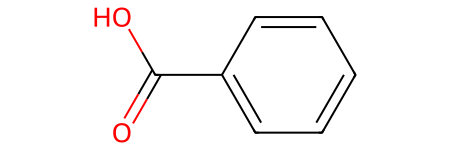

In [13]:
# Compuestos de filtro que contienen un grupo funcional ácido
acid = AllChem.MolFromSmiles("c1ccccc1C(=O)O")
acid

In [14]:
#Creamos un nuevo dataset donde adicionaremos las moléculas filtradas
dataset_acid = dataset[dataset["Structure"] >= acid]
dataset_acid.shape

(170, 3)

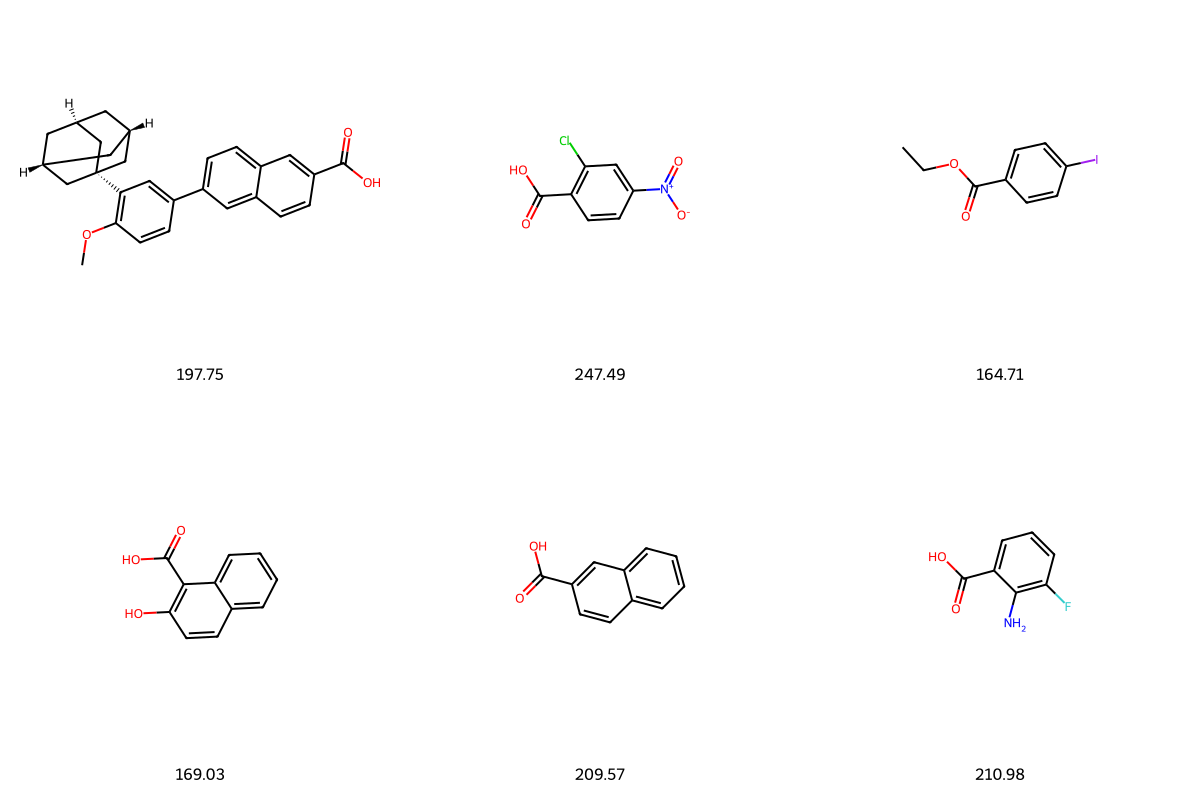

In [15]:
#Visualizamos los elementos filtrados
from rdkit.Chem import Draw
Draw.MolsToGridImage([x for x in dataset_acid["Structure"]][:6], maxMols=100,
                     legends=[str(x) for x in round(dataset_cs.Energygap,2)], subImgSize=(400,400), molsPerRow=3)

# Conclusión

Hemos aprendido a calcular huellas dactilares moleculares (claves MACCS, Avalon, pares de átomos, torsiones topológicas y huellas dactilares de Morgan) usando RDKit para una sola molécula o varias moléculas. También vimos cómo calcular el coeficiente de Tanimoto y la agrupación de Taylor-Butina y el filtrado de moléculas por contenido de segmentos

<div style="background-color:lightgreen; border-style: dotted;border-color: yellow;text-align:center;color:blue;font-size:20px;border-radius: 50px;padding: 20px 20px;"><strong> Tomado originalmente de
Gashaw M. Goshu, Ph.D. in Chemistry </strong></div> https://www.youtube.com/watch?v=-oHqQBUyrQ0 , adaptado por el Dr. Erick Correa para el curso de Desarrollo de Fármacos Asistido por Computadora Laboratorio de Síntesis de Fármacos L-9, F.E.S. Zaragoza UNAM

